# Programação para Engenharia Elétrica
## Aula: Dicionários, arquivos CSV e introdução à análise de dados

Nesta aula, vamos avançar a partir de listas, variáveis, `for` e `if` para organizar dados de medições elétricas e analisá-los com **Pandas**.

### Objetivos
- Entender o que é um dicionário em Python.
- Ler dados organizados em um arquivo CSV.
- Conhecer um DataFrame do Pandas.
- Explorar dados de medições elétricas.
- Calcular estatísticas simples e construir um gráfico.

**Contexto:** um técnico registrou medições de tensão, corrente e potência em diferentes horários. Vamos usar esses dados para praticar." 

## 1. Relembrando listas

Uma lista armazena vários valores em uma sequência. Podemos acessar cada valor pela sua posição.

In [2]:
tensoes = [218, 220, 221, 219, 223]

print("Primeira medição:", tensoes[0], "V")
print("Quantidade de medições:", len(tensoes))

for tensao in tensoes:
    print(f"Tensão: {tensao} V")

Primeira medição: 218 V
Quantidade de medições: 5
Tensão: 218 V
Tensão: 220 V
Tensão: 221 V
Tensão: 219 V
Tensão: 223 V


### Quando uma lista não é suficiente?

Imagine que queremos registrar, para cada medição, o horário, a tensão, a corrente e a potência. Uma lista simples não deixa claro o significado de cada valor.

Para organizar informações usando **nomes**, podemos utilizar um dicionário.

## 2. Dicionários em Python

Um dicionário armazena pares de **chave e valor**. A chave funciona como um rótulo para encontrar uma informação.

Exemplo: `{"tensao": 220, "corrente": 2.5}`

- `"tensao"` e `"corrente"` são chaves.
- `220` e `2.5` são valores.
- As chaves são escritas entre aspas quando são textos.
- Acessamos um valor usando sua chave.

In [3]:
medicao = {
    "horario": "08:00",
    "tensao": 220,
    "corrente": 2.5
}

print("Horário:", medicao["horario"])
print("Tensão:", medicao["tensao"], "V")
print("Corrente:", medicao["corrente"], "A")

Horário: 08:00
Tensão: 220 V
Corrente: 2.5 A


### Adicionar e alterar informações

Podemos adicionar uma nova chave ou atualizar um valor já existente.

In [4]:
medicao["potencia"] = medicao["tensao"] * medicao["corrente"]
medicao["corrente"] = 2.7

print(medicao)

{'horario': '08:00', 'tensao': 220, 'corrente': 2.7, 'potencia': 550.0}


### Uma lista de dicionários

Quando temos várias medições, podemos guardar cada uma em um dicionário e colocar todos eles em uma lista. Cada dicionário representa uma medição.

In [5]:
medicoes = [
    {"horario": "08:00", "tensao": 220, "corrente": 2.0},
    {"horario": "09:00", "tensao": 218, "corrente": 2.4},
    {"horario": "10:00", "tensao": 221, "corrente": 1.8}
]

for item in medicoes:
    potencia = item["tensao"] * item["corrente"]
    print(
        f'{item["horario"]}: '
        f'{item["tensao"]} V, {item["corrente"]} A, '
        f'{potencia:.1f} W (potência estimada)'
    )

08:00: 220 V, 2.0 A, 440.0 W (potência estimada)
09:00: 218 V, 2.4 A, 523.2 W (potência estimada)
10:00: 221 V, 1.8 A, 397.8 W (potência estimada)


### Exercício 1 — Dicionários

Crie um dicionário chamado `resistor` com as chaves `resistencia` e `potencia_nominal`. Use os valores 100 (ohms) e 0.25 (watts).

1. Mostre a resistência na tela.
2. Adicione uma chave chamada `corrente` com o valor calculado para uma tensão de 12 V, usando a Lei de Ohm: `I = V / R`.
3. Mostre o dicionário completo.

**Tente resolver antes de consultar a solução.**

In [ ]:
# Escreva sua solução aqui



### Dicionários e Pandas

Podemos combinar **dicionários** e **Pandas** para organizar informações e criar um DataFrame.

**O que é Pandas?**

Pandas é uma biblioteca Python utilizada para organizar, manipular e analisar dados. Ela facilita tarefas como ler arquivos CSV, calcular estatísticas e filtrar informações.

**O que é um DataFrame?**

Um DataFrame é uma estrutura de dados do Pandas organizada em linhas e colunas, semelhante a uma tabela. Cada linha representa um registro, enquanto cada coluna representa uma variável.

Nesse exemplo, cada dicionário representa uma medição elétrica, e o Pandas reúne as medições em um DataFrame para facilitar a análise dos dados.

In [6]:
import pandas as pd

medicoes = [
    {"tensao_V": 127, "corrente_A": 2.5},
    {"tensao_V": 220, "corrente_A": 1.2},
    {"tensao_V": 110, "corrente_A": 3.0}
]

df = pd.DataFrame(medicoes)

print(df)

   tensao_V  corrente_A
0       127         2.5
1       220         1.2
2       110         3.0


## 3. O que é um arquivo CSV?

CSV é um formato de arquivo tabular em que cada linha representa um registro e os valores são separados por um delimitador, geralmente vírgula ou ponto e vírgula.

Exemplo de conteúdo de um arquivo `medicoes_eletricas.csv`:

```text
horario,tensao_V,corrente_A
08:00,220,2.0
09:00,218,2.4
10:00,221,1.8
11:00,219,2.2
```

Esse formato é comum para guardar medições de sensores, equipamentos e experimentos. Cada coluna representa uma variável e cada linha representa uma observação.

## 4. Lendo um CSV com Pandas

O Pandas é uma biblioteca Python usada para organizar e analisar dados tabulares. Sua estrutura principal é o **DataFrame**, que se parece com uma tabela.

Primeiro, vamos criar um arquivo CSV real na pasta do notebook e, em seguida, abri-lo com `pd.read_csv()`.

In [7]:
import pandas as pd

# Ler o arquivo CSV salvo na mesma pasta deste notebook
df = pd.read_csv("medicoes_eletricas.csv")

display(df)

,horario,tensao_V,corrente_A
0,08:00,220,2.0
1,09:00,218,2.4
2,10:00,221,1.8
3,11:00,219,2.2
4,12:00,223,2.1
5,13:00,217,2.6


### Conhecendo a tabela

Alguns comandos úteis para a primeira exploração:

- `df.head()` mostra as primeiras linhas.
- `df.shape` retorna a quantidade de linhas e colunas.
- `df.columns` mostra os nomes das colunas.
- `df.info()` mostra os tipos de dados e a quantidade de valores não nulos.
- `df.describe()` resume estatísticas das colunas numéricas.

In [8]:
print("Primeiras linhas:")
display(df.head())

print("Dimensões (linhas, colunas):", df.shape)
print("Colunas:", list(df.columns))

print("\nInformações sobre as colunas:")
df.info()

print("\nEstatísticas descritivas:")
display(df.describe())

Primeiras linhas:


,horario,tensao_V,corrente_A
0,08:00,220,2.0
1,09:00,218,2.4
2,10:00,221,1.8
3,11:00,219,2.2
4,12:00,223,2.1


Dimensões (linhas, colunas): (6, 3)
Colunas: ['horario', 'tensao_V', 'corrente_A']

Informações sobre as colunas:
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horario     6 non-null      str    
 1   tensao_V    6 non-null      int64  
 2   corrente_A  6 non-null      float64
dtypes: float64(1), int64(1), str(1)
memory usage: 306.0 bytes

Estatísticas descritivas:


,tensao_V,corrente_A
count,6.000000,6.000000
mean,219.666667,2.183333
std,2.160247,0.285774
min,217.000000,1.800000
25%,218.250000,2.025000
50%,219.500000,2.150000
75%,220.750000,2.350000
max,223.000000,2.600000


## 5. Selecionando colunas e criando variáveis

Podemos selecionar uma coluna pelo nome. O resultado é uma série de valores. Também podemos criar uma nova coluna a partir de cálculos.

In [9]:
# Selecionar apenas a coluna de tensão
df["tensao_V"]

0    220
1    218
2    221
3    219
4    223
5    217
Name: tensao_V, dtype: int64

In [10]:
# Calcular a potência aproximada: P = V × I
df["potencia_W"] = df["tensao_V"] * df["corrente_A"]

display(df)

,horario,tensao_V,corrente_A,potencia_W
0,08:00,220,2.0,440.0
1,09:00,218,2.4,523.2
2,10:00,221,1.8,397.8
3,11:00,219,2.2,481.8
4,12:00,223,2.1,468.3
5,13:00,217,2.6,564.2


## 6. Estatísticas iniciais

Vamos calcular medidas simples para compreender as medições de tensão e potência.

- **Média:** valor médio das observações.
- **Mediana:** valor central quando os dados são ordenados.
- **Mínimo e máximo:** menores e maiores valores observados.
- **Desvio-padrão:** indica o quanto os valores variam em torno da média.

Essas medidas descrevem os dados disponíveis, mas não explicam sozinhas por que as medições variam.

In [11]:
for coluna in ["tensao_V", "corrente_A", "potencia_W"]:
    print(f"\nEstatísticas de {coluna}")
    print(f"Média:   {df[coluna].mean():.2f}")
    print(f"Mediana: {df[coluna].median():.2f}")
    print(f"Mínimo:  {df[coluna].min():.2f}")
    print(f"Máximo:  {df[coluna].max():.2f}")
    print(f"Desvio-padrão: {df[coluna].std():.2f}")


Estatísticas de tensao_V
Média:   219.67
Mediana: 219.50
Mínimo:  217.00
Máximo:  223.00
Desvio-padrão: 2.16

Estatísticas de corrente_A
Média:   2.18
Mediana: 2.15
Mínimo:  1.80
Máximo:  2.60
Desvio-padrão: 0.29

Estatísticas de potencia_W
Média:   479.22
Mediana: 475.05
Mínimo:  397.80
Máximo:  564.20
Desvio-padrão: 59.07


## 7. Visualizando os dados

Um gráfico ajuda a perceber variações que podem ser difíceis de identificar apenas em uma tabela. Vamos representar a tensão ao longo das medições.

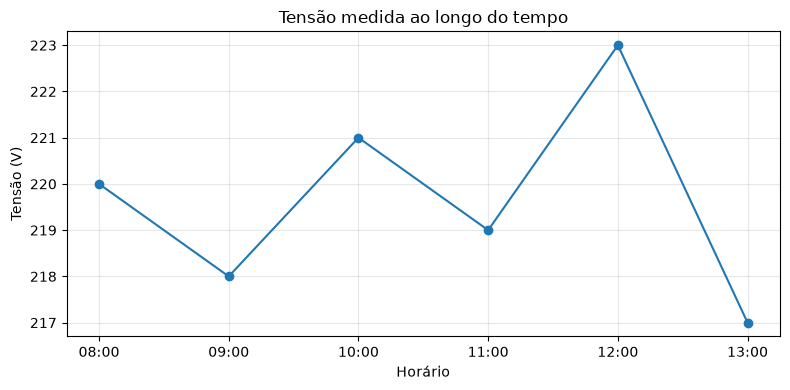

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(df["horario"], df["tensao_V"], marker="o")
plt.title("Tensão medida ao longo do tempo")
plt.xlabel("Horário")
plt.ylabel("Tensão (V)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Selecionando dados com `loc` e `iloc`

O Pandas permite selecionar linhas e colunas específicas de um DataFrame.

- `loc`: seleciona dados pelos rótulos dos índices e pelos nomes das colunas.
- `iloc`: seleciona dados pelas posições numéricas das linhas e colunas.

Para entender a diferença, vamos utilizar um exemplo de medições elétricas.


In [21]:
import pandas as pd

df = pd.DataFrame({
    "horario": ["08:00", "08:05", "08:10"],
    "tensao_V": [127, 220, 110],
    "corrente_A": [2.5, 1.2, 3.0]
})

df

,horario,tensao_V,corrente_A
0,08:00,127,2.5
1,08:05,220,1.2
2,08:10,110,3.0



### Selecionando dados com `iloc`

O `iloc` utiliza a posição numérica. A contagem começa em zero, então a posição `0` corresponde à primeira linha e a posição `1` corresponde à segunda linha.


In [22]:
# Selecionar a segunda linha
df.iloc[1]

horario       08:05
tensao_V        220
corrente_A      1.2
Name: 1, dtype: object

In [23]:
# Selecionar apenas a tensão da segunda linha
df.iloc[1, 1]

np.int64(220)

In [24]:
# Selecionar as duas primeiras linhas
df.iloc[0:2]

,horario,tensao_V,corrente_A
0,08:00,127,2.5
1,08:05,220,1.2



### Selecionando dados com `loc`

O `loc` utiliza os rótulos dos índices e os nomes das colunas para localizar os dados.


In [25]:
# Selecionar a linha cujo índice é 1
df.loc[1]

horario       08:05
tensao_V        220
corrente_A      1.2
Name: 1, dtype: object

In [26]:
# Selecionar a tensão da linha de índice 1
df.loc[1, "tensao_V"]

np.int64(220)

In [27]:
# Selecionar tensão e corrente da linha de índice 1
df.loc[1, ["tensao_V", "corrente_A"]]

tensao_V      220.0
corrente_A      1.2
Name: 1, dtype: float64


### Entendendo a diferença

Quando o índice segue a sequência `0, 1, 2`, os comandos `loc[1]` e `iloc[1]` retornam a mesma linha.

Entretanto, podemos utilizar índices diferentes para observar como cada método funciona.


## Exercício 3 — Investigue as medições

Um técnico considera que a tensão de operação esperada é de 210 V a 230 V.

Usando o DataFrame do Exercício 2:
1. Percorra as medições com um `for`.
2. Use `if` para identificar tensões dentro ou fora desse intervalo.
3. Mostre o horário, a tensão e a classificação.
4. Compare a solução usando um laço com uma abordagem usando Pandas, por exemplo `df[df["tensao_V"] < 210]`.

Explique em uma ou duas frases qual abordagem foi mais simples para essa tarefa.

In [ ]:
# Escreva sua solução aqui



## Resumo da aula

Nesta aula, você praticou:

- **Dicionários:** armazenar informações usando pares de chave e valor.
- **Listas de dicionários:** representar vários registros estruturados.
- **CSV:** organizar dados em linhas e colunas.
- **Pandas:** carregar e explorar dados com `read_csv()`, `head()`, `info()`, `shape` e `describe()`.
- **Análise inicial:** selecionar colunas, criar variáveis calculadas, calcular estatísticas e visualizar medições.

Antes de entregar os exercícios, confira se os resultados são coerentes com os dados e se você consegue explicar o que cada parte do código realiza.